# Análisis exploratorio de datos (EDA) — Airbnb Bogotá, D.C.

**Inteligencia de Negocios · Taller evaluativo 2 · Proceso ETL**

**Objetivo:** comprender la estructura, la calidad y la distribución de los datos de Airbnb
para Bogotá **antes** de transformarlos, y justificar con evidencia cada decisión que se
implementa en `src/transformacion.py`.

**Fuente:** [Inside Airbnb](https://insideairbnb.com/get-the-data/) — scrape del 21-22 de junio de 2026.
Los archivos `listings.csv.gz`, `calendar.csv.gz` y `reviews.csv.gz` se cargaron en la base
de datos **MongoDB local `airbnb_bogota_etl`** (colecciones `Listings`, `Calendar` y `Reviews`)
con `src/cargar_mongo.py`. **Este notebook lee los datos desde MongoDB, no desde los CSV**,
usando la misma clase `Extraccion` del proceso ETL.

**Contenido**
1. Extracción desde MongoDB
2. Entendimiento general de los datos (2.1)
3. Calidad de los datos (2.2): nulos, duplicados, atípicos, inconsistencias
4. Distribuciones y relaciones (precio, localidad, tipo de alojamiento, correlaciones, amenities, anfitriones)
5. Análisis temporal (reseñas y calendario)
6. Posibles transformaciones (2.3)
7. Hallazgos y decisiones para la fase de transformación (2.4)
8. Verificación del resultado del ETL

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from extraccion import Extraccion
from config import DIR_FIGURAS, RUTA_SQLITE, MAX_FILAS_EXCEL

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

AZUL = "#2a78d6"
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
ROJO, GRIS = "#e34948", "#c3c2b7"
TINTA, TINTA_2, TINTA_SUAVE, GRILLA, FONDO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SECUENCIAL = LinearSegmentedColormap.from_list("azules", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=PALETA), "lines.linewidth": 2,
    "figure.dpi": 100, "legend.frameon": False,
})
COP = mticker.FuncFormatter(lambda x, _: f"${x/1e6:,.0f}M" if abs(x) >= 1e6 else f"${x/1000:,.0f}k")
PCT = mticker.PercentFormatter(1.0)

DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

## 1. Extracción desde MongoDB

Se usa la clase `Extraccion` (`src/extraccion.py`): abre la conexión, consulta cada colección
y la convierte en DataFrame, registrando en `logs/` la conexión y los registros extraídos.
El calendario se trae por bloques y con `date`/`available` como categóricas para no
agotar la memoria (son ~7 millones de documentos).

In [2]:
with Extraccion() as ext:
    listings = ext.extraer_listings()
    calendar = ext.extraer_calendar()
    reviews = ext.extraer_reviews()

resumen = pd.DataFrame({
    "coleccion": ["Listings", "Calendar", "Reviews"],
    "registros": [len(listings), len(calendar), len(reviews)],
    "columnas": [listings.shape[1], calendar.shape[1], reviews.shape[1]],
    "memoria_MB": [round(d.memory_usage(deep=True).sum() / 1e6, 1) for d in (listings, calendar, reviews)],
})
resumen

2026-10-06 21:52:52 | INFO     | etl | Archivo de log de esta ejecución: C:\Users\Admin\Documents\ITM\Inteligencia de Negocios\Taller 2 Proceso ETL\etl_airbnb\logs\log_20261006_2152.txt


2026-10-06 21:52:52 | INFO     | etl.extraccion | Conexión exitosa a MongoDB mongodb://localhost:27017/ (versión 8.3.8), base de datos 'airbnb_bogota_etl'


2026-10-06 21:52:52 | INFO     | etl.extraccion | Colecciones disponibles: ['Calendar', 'Listings', 'Reviews']


2026-10-06 21:52:53 | INFO     | etl.extraccion | Colección 'Listings': 19,187 registros y 90 columnas extraídos (0.9s)


2026-10-06 21:53:28 | INFO     | etl.extraccion | Colección 'Calendar': 7,003,255 registros y 5 columnas extraídos (35.1s)


2026-10-06 21:53:31 | INFO     | etl.extraccion | Colección 'Reviews': 527,731 registros y 6 columnas extraídos (3.5s)


2026-10-06 21:53:31 | INFO     | etl.extraccion | Conexión a MongoDB cerrada


,coleccion,registros,columnas,memoria_MB
0,Listings,19187,90,86.50
1,Calendar,7003255,5,189.10
2,Reviews,527731,6,208.80


## 2. Entendimiento general de los datos (2.1)

### 2.1.1 Listings — un registro por alojamiento

In [3]:
listings.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,None,https://a0.muscache.com/pictures/38377482/1df3...,113734,https://www.airbnb.com/users/show/113734,1462509905126026119,https://www.airbnb.com/users/profile/146250990...,Marcela,None,16,1,15.00,5.00,"Bogota, Colombia","I am an Architect and Urban Planner ,with my o...",None,None,None,t,None,https://a0.muscache.com/im/users/113734/profil...,None,3,None,None,t,t,None,Chapinero,None,4.66,-74.05,Entire serviced apartment,Entire home/apt,4,NaN,2.5 baths,2.00,3.00,"[""Blender"", ""Luggage dropoff allowed"", ""Long t...","$284,294.01",2027-04-01,2027-04-29,"7,960,232.40","284,294.01","{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...",28.00,"1,000.00",28.00,28.00,"1,000.00","1,000.00",28.00,"1,000.00",None,t,0,0,0,82,2026-06-22,45,2,0,0,2,112,"31,840,929.00",2010-10-06,2025-09-14,4.87,4.84,4.91,4.93,4.81,4.93,4.81,"112,727.00",None,3,3,0,0,0.24
1,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",None,https://a0.muscache.com/pictures/miso/Hosting-...,321447,https://www.airbnb.com/users/show/321447,1462515641808590179,https://www.airbnb.com/users/profile/146251564...,Teresa,None,15,6,15.00,5.00,"Bogotá, Colombia",I'm a person that is always looking to enrich ...,None,None,None,t,None,https://a0.muscache.com/im/pictures/user/9bf8f...,None,24,None,None,t,t,None,Candelaria,None,4.59,-74.07,Entire loft,Entire home/apt,3,1.00,1 bath,1.00,1.00,"[""Blender"", ""Luggage dropoff allowed"", ""Long t...","$215,000.00",2026-06-27,2026-06-28,"215,000.00","215,000.00","{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...",1.00,"1,125.00",1.00,1.00,"1,125.00","1,125.00",1.00,"1,125.00",None,t,8,15,31,236,2026-06-22,33,0,0,67,1,0,0.00,2012-02-18,2025-04-28,4.75,4.67,4.81,4.91,4.73,4.79,4.70,"100,613.00",None,24,22,2,0,0.19
2,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,None,https://a0.muscache.com/pictures/24594394/1ace...,676823,https://www.airbnb.com/users/show/676823,1462513470872353935,https://www.airbnb.co

In [4]:
print(f"Registros: {listings.shape[0]:,} | Columnas: {listings.shape[1]}")
listings.info()

Registros: 19,187 | Columnas: 90
<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            19187 non-null  int64  
 1   listing_url                                   19187 non-null  str    
 2   scrape_id                                     19187 non-null  int64  
 3   last_scraped                                  19187 non-null  str    
 4   source                                        19187 non-null  str    
 5   name                                          19187 non-null  str    
 6   description                                   18664 non-null  str    
 7   neighborhood_overview                         0 non-null      object 
 8   picture_url                                   19187 non-null  str    
 9   host_id                                

`info()` muestra que **`price` llega como texto** (`str`), igual que las fechas
(`last_scraped`, `first_review`, `last_review`) y los booleanos (`'t'`/`'f'`). Varias columnas
tienen **0 valores no nulos**: están completamente vacías en este scrape.

Para describir el precio se hace aquí una conversión *exploratoria* (en el ETL formal la hace
`Transformacion.normalizar_precio`):

In [5]:
listings["price_num"] = pd.to_numeric(listings["price"].str.replace(r"[\$,]", "", regex=True), errors="coerce")

variables_clave = ["price_num", "accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights",
                   "maximum_nights", "availability_365", "number_of_reviews", "review_scores_rating",
                   "reviews_per_month", "calculated_host_listings_count", "estimated_occupancy_l365d",
                   "estimated_revenue_l365d"]
listings[variables_clave].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
price_num,"18,992.00","446,026.55","8,829,056.71","19,181.11","37,610.03","110,000.00","161,460.00","230,346.38","1,330,087.13","448,176,567.00"
accommodates,"19,187.00",3.11,2.09,1.00,1.00,2.00,2.00,4.00,14.00,16.00
bedrooms,"16,228.00",1.54,1.60,1.00,1.00,1.00,1.00,2.00,7.00,50.00
beds,"18,896.00",1.95,2.09,1.00,1.00,1.00,1.00,2.00,10.00,50.00
bathrooms,"18,121.00",1.42,1.38,0.50,1.00,1.00,1.00,1.50,5.00,50.00
minimum_nights,"19,183.00",6.98,10.99,1.00,1.00,1.00,1.00,3.00,30.00,32.00
maximum_nights,"19,183.00","448,500.35","31,007,553.96",2.00,25.00,365.00,365.00,"1,125.00","1,125.00","2,147,483,647.00"
availability_365,"19,187.00",306.95,82.07,0.00,49.86,269.00,349.00,363.00,365.00,365.00
number_of_reviews,"19,187.00",27.50,74.00,0.00,0.00,1.00,8.00,31.00,243.00,"6,162.00"
review_scores_rating,"14,922.00",4.70,0.47,1.00,3.00,4.64,4.83,4.98,5.00,5.00


In [6]:
for col in ["room_type", "neighbourhood_cleansed", "host_is_superhost", "has_availability"]:
    print(f"\n--- {col} ---")
    print(listings[col].value_counts(dropna=False).head(10).to_string())


--- room_type ---
room_type
Entire home/apt    13865
Private room        5172
Shared room          117
Hotel room            33

--- neighbourhood_cleansed ---
neighbourhood_cleansed
Chapinero         5097
Usaquen           3582
Teusaquillo       2779
Santa Fe          1453
Suba              1274
Engativa          1211
Barrios Unidos    1036
Fontibon           969
Candelaria         700
Kennedy            313

--- host_is_superhost ---
host_is_superhost
f    12877
t     6310

--- has_availability ---
has_availability
t      19057
NaN      130


**Variables más relevantes de Listings**

| Variable | Tipo | Descripción | Observación inicial |
|---|---|---|---|
| `id` / `host_id` | entero | Identificador del alojamiento / anfitrión | Llaves para unir con Calendar y Reviews |
| `price` | texto | Precio por noche en COP (`"$284,294.01"`) | Debe normalizarse a número |
| `room_type` | categórica | Apartamento completo, habitación privada, compartida, hotel | 72 % son apartamentos completos |
| `neighbourhood_cleansed` | categórica | Localidad de Bogotá (20) | Nombres sin tildes |
| `latitude` / `longitude` | numérica | Ubicación | Permite análisis espacial |
| `accommodates`, `bedrooms`, `beds`, `bathrooms` | numérica | Capacidad | `bedrooms` y `bathrooms` con nulos |
| `minimum_nights` / `maximum_nights` | numérica | Restricciones de estadía | `maximum_nights` con valores técnicos absurdos |
| `availability_365` | numérica | Días disponibles en los próximos 365 | Muchos alojamientos 100 % disponibles |
| `number_of_reviews`, `review_scores_*` | numérica | Volumen y calificación de reseñas | Nulos cuando no hay reseñas |
| `amenities` | texto JSON | Lista de servicios del alojamiento | Campo anidado |
| `host_*` | mixta | Información del anfitrión | Se repite por cada alojamiento del host |
| `price_quote_raw` | texto JSON | Cotización detallada de Airbnb | Campo anidado |

La mediana del precio (~161 mil COP) es mucho menor que la media (~446 mil COP): la distribución
está fuertemente sesgada por unos pocos valores extremos (máximo de **448 millones COP por noche**,
claramente un error de captura).

### 2.1.2 Calendar — un registro por alojamiento y día

In [7]:
display(calendar.head())
print(f"Registros: {calendar.shape[0]:,} | Columnas: {calendar.shape[1]}")
calendar.info()

,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,f,2,1125
1,15410909,2026-06-23,f,2,1125
2,15410909,2026-06-24,f,2,1125
3,15410909,2026-06-25,t,2,1125
4,15410909,2026-06-26,t,2,1125


Registros: 7,003,255 | Columnas: 5
<class 'pandas.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Data columns (total 5 columns):
 #   Column          Dtype   
---  ------          -----   
 0   listing_id      int64   
 1   date            category
 2   available       category
 3   minimum_nights  int64   
 4   maximum_nights  int64   
dtypes: category(2), int64(3)
memory usage: 180.3 MB


In [8]:
fechas = pd.to_datetime(calendar["date"].cat.categories)
print("Rango de fechas:", fechas.min().date(), "a", fechas.max().date())
print("Alojamientos distintos:", f"{calendar['listing_id'].nunique():,}")
print("Días por alojamiento:", calendar.groupby("listing_id").size().describe()[["min", "max"]].to_dict())
print("\nDisponibilidad (t = disponible, f = no disponible):")
print(calendar["available"].value_counts(normalize=True).round(3).to_string())
calendar[["minimum_nights", "maximum_nights"]].describe().T

Rango de fechas: 2026-06-21 a 2027-06-21
Alojamientos distintos: 19,187


Días por alojamiento: {'min': 365.0, 'max': 365.0}

Disponibilidad (t = disponible, f = no disponible):


available
t   0.84
f   0.16


,count,mean,std,min,25%,50%,75%,max
minimum_nights,"7,003,255.00",7.25,11.66,1.00,1.00,2.00,4.00,365.00
maximum_nights,"7,003,255.00","447,784.59","30,982,278.40",1.00,365.00,365.00,"1,125.00","2,147,483,647.00"


El calendario cubre **un año hacia adelante** (21-jun-2026 a 21-jun-2027) para los 19.187
alojamientos (exactamente 365 días cada uno). **A diferencia de versiones anteriores de Inside
Airbnb, este scrape no trae precio diario**: solo `available`, `minimum_nights` y
`maximum_nights`. Por eso el precio para análisis de ingresos debe tomarse de Listings.
`available = 'f'` significa *no disponible*, que puede ser una reserva o un bloqueo del anfitrión.

### 2.1.3 Reviews — un registro por reseña

In [9]:
display(reviews.head())
print(f"Registros: {reviews.shape[0]:,} | Columnas: {reviews.shape[1]}")
reviews.info()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."
3,27841,225796,2011-04-13,471115,Tiffany,Marcela was a lovely and gracious host. She me...
4,27841,952928,2012-02-27,1098411,Sarah,Marcela is the perfect host and has a gorgeuos...


Registros: 527,731 | Columnas: 6
<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   listing_id     527731 non-null  int64
 1   id             527731 non-null  int64
 2   date           527731 non-null  str  
 3   reviewer_id    527731 non-null  int64
 4   reviewer_name  527731 non-null  str  
 5   comments       527540 non-null  str  
dtypes: int64(3), str(3)
memory usage: 24.2 MB


In [10]:
print("Rango de fechas:", reviews["date"].min(), "a", reviews["date"].max())
print("Alojamientos con reseñas:", f"{reviews['listing_id'].nunique():,}")
print("Reseñadores distintos:", f"{reviews['reviewer_id'].nunique():,}")
reviews["comments"].str.len().describe(percentiles=[.25, .5, .75, .99]).to_frame("longitud_comentario").T

Rango de fechas: 2010-10-06 a 2026-06-21
Alojamientos con reseñas: 14,922
Reseñadores distintos: 371,567


,count,mean,std,min,25%,50%,75%,99%,max
longitud_comentario,"527,540.00",160.75,183.35,1.00,45.00,103.00,206.00,937.00,"5,632.00"


Hay **527.731 reseñas entre 2010 y junio de 2026**. Los comentarios tienen una longitud mediana
de ~100 caracteres, pero hay comentarios de hasta 5.600 caracteres y otros de un solo carácter.

## 3. Calidad de los datos (2.2)

### 3.1 Valores nulos o faltantes por columna

In [11]:
nulos = (listings.drop(columns="price_num").isna().agg(["sum", "mean"]).T
         .rename(columns={"sum": "nulos", "mean": "porcentaje"}))
nulos = nulos[nulos["nulos"] > 0].sort_values("porcentaje", ascending=False)
nulos["porcentaje"] = (nulos["porcentaje"] * 100).round(1)
print(f"Columnas con nulos: {len(nulos)} de {listings.shape[1] - 1} | "
      f"columnas 100 % vacías: {(nulos['porcentaje'] == 100).sum()}")
nulos

Columnas con nulos: 47 de 90 | columnas 100 % vacías: 13


,nulos,porcentaje
neighborhood_overview,"19,187.00",100.00
host_since,"19,187.00",100.00
host_neighbourhood,"19,187.00",100.00
host_thumbnail_url,"19,187.00",100.00
host_acceptance_rate,"19,187.00",100.00
host_response_rate,"19,187.00",100.00
host_response_time,"19,187.00",100.00
host_verifications,"19,187.00",100.00
host_total_listings_count,"19,187.00",100.00
neighbourhood,"19,187.00",100.00


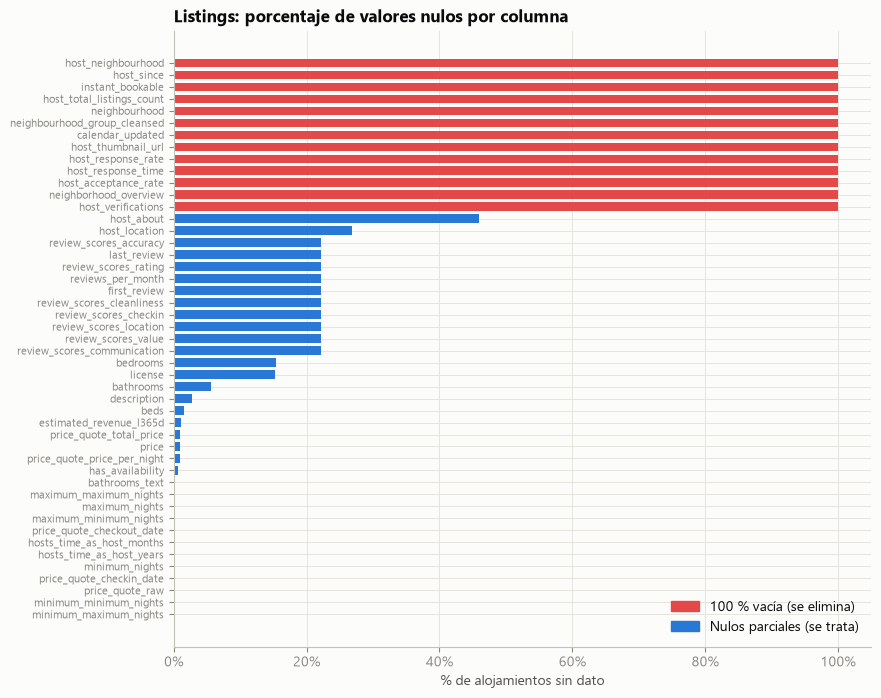

In [12]:
fig, ax = plt.subplots(figsize=(9, 8))
datos = nulos.sort_values("porcentaje")
colores = [ROJO if p == 100 else AZUL for p in datos["porcentaje"]]
ax.barh(datos.index, datos["porcentaje"] / 100, color=colores, height=0.7)
ax.xaxis.set_major_formatter(PCT)
ax.set_title("Listings: porcentaje de valores nulos por columna")
ax.set_xlabel("% de alojamientos sin dato")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ROJO, label="100 % vacía (se elimina)"),
                   Patch(color=AZUL, label="Nulos parciales (se trata)")], loc="lower right")
ax.tick_params(axis="y", labelsize=8)
guardar(fig, "fig01_nulos_listings")
plt.show()

In [13]:
print("Nulos en Calendar:\n", calendar.isna().sum().to_string())
print("\nNulos en Reviews:\n", reviews.isna().sum().to_string())

sin_resenas = listings["number_of_reviews"] == 0
print(f"\nAlojamientos sin reseñas: {sin_resenas.sum():,}")
print(f"Nulos en review_scores_rating: {listings['review_scores_rating'].isna().sum():,}")
print(f"De ellos, sin reseñas: {(listings['review_scores_rating'].isna() & sin_resenas).sum():,}")

Nulos en Calendar:
 listing_id        0
date              0
available         0
minimum_nights    0
maximum_nights    0

Nulos en Reviews:
 listing_id         0
id                 0
date               0
reviewer_id        0
reviewer_name      0
comments         191

Alojamientos sin reseñas: 4,265
Nulos en review_scores_rating: 4,265
De ellos, sin reseñas: 4,265


**Interpretación**

- **13 columnas están 100 % vacías** (`host_since`, `host_response_rate`, `host_acceptance_rate`,
  `neighbourhood`, `calendar_updated`, `instant_bookable`, `host_verifications`, …). Inside Airbnb dejó
  de publicarlas en este scrape; no hay forma de imputarlas → **se eliminan**.
- **~22 % de nulos en `review_scores_*`, `first_review`, `last_review` y `reviews_per_month`**:
  coinciden con los alojamientos **sin ninguna reseña**. No es información perdida sino ausencia
  de calificación → **no se imputan** (inventar una calificación sesgaría el análisis); se crea la
  bandera `tiene_resenas` y `reviews_per_month` se llena con 0.
- `host_location` (~27 %) y `host_about` (~46 %) son textos opcionales del perfil → "No especificado".
- `bedrooms` (~15 %) y `bathrooms` (~6 %) son atributos físicos imputables: `bathrooms` se recupera
  desde el texto `bathrooms_text`; `bedrooms`/`beds` con la mediana según capacidad (`accommodates`).
- **`price` tiene 195 nulos** (1 %); ninguno tiene cotización alternativa (`price_quote_price_per_night`
  también es nulo) → se imputan con la mediana de su localidad y tipo de habitación, marcándolos.
- **Calendar no tiene nulos. Reviews solo tiene 191 comentarios nulos**: la reseña sigue siendo
  evidencia de una estadía, así que se conserva la fila con el texto "Sin comentario".

### 3.2 Registros duplicados

In [14]:
duplicados = pd.DataFrame([
    {"coleccion": "Listings", "llave": "id",
     "duplicados_exactos": listings.drop(columns="price_num").duplicated().sum(),
     "duplicados_por_llave": listings["id"].duplicated().sum()},
    {"coleccion": "Calendar", "llave": "listing_id + date",
     "duplicados_exactos": (dup_cal := calendar.duplicated(subset=["listing_id", "date"]).sum()),
     "duplicados_por_llave": dup_cal},
    {"coleccion": "Reviews", "llave": "id",
     "duplicados_exactos": reviews.duplicated().sum(),
     "duplicados_por_llave": reviews["id"].duplicated().sum()},
])
huerfanos_cal = (~calendar["listing_id"].isin(listings["id"])).sum()
huerfanos_rev = (~reviews["listing_id"].isin(listings["id"])).sum()
print(f"Filas de Calendar sin alojamiento en Listings: {huerfanos_cal:,}")
print(f"Reseñas sin alojamiento en Listings: {huerfanos_rev:,}")
duplicados

Filas de Calendar sin alojamiento en Listings: 0
Reseñas sin alojamiento en Listings: 0


,coleccion,llave,duplicados_exactos,duplicados_por_llave
0,Listings,id,0,0
1,Calendar,listing_id + date,0,0
2,Reviews,id,0,0


**Interpretación y decisión:** no hay duplicados exactos ni por llave de negocio en ninguna
colección, y todas las filas de Calendar y Reviews referencian alojamientos existentes
(integridad referencial correcta). **Por ahora no es necesario eliminar duplicados**, pero el
control se mantiene en `Transformacion.eliminar_duplicados` y en la verificación de integridad:
si una carga futura de MongoDB se ejecuta dos veces o trae reseñas de alojamientos dados de baja,
el ETL los detecta, los elimina y lo registra como WARNING.

### 3.3 Posibles valores atípicos: `price`, `minimum_nights`, `availability_365`

Se usa el criterio del rango intercuartílico (IQR): un valor es atípico si está por fuera de
[Q1 − 1,5·IQR, Q3 + 1,5·IQR]. Para el precio, por su fuerte asimetría, se calcula también sobre
el logaritmo.

In [15]:
def resumen_iqr(serie, nombre, log=False):
    s = np.log(serie.dropna()) if log else serie.dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    if log:
        inf, sup = np.exp(inf), np.exp(sup)
    x = serie.dropna()
    return {"variable": nombre, "min": x.min(), "Q1": x.quantile(.25), "mediana": x.median(),
            "Q3": x.quantile(.75), "max": x.max(), "lim_inferior": inf, "lim_superior": sup,
            "atipicos": int(((x < inf) | (x > sup)).sum()),
            "pct_atipicos": round(((x < inf) | (x > sup)).mean() * 100, 2)}

atipicos = pd.DataFrame([
    resumen_iqr(listings["price_num"], "price (COP)"),
    resumen_iqr(listings["price_num"], "price (COP, IQR en log)", log=True),
    resumen_iqr(listings["minimum_nights"], "minimum_nights"),
    resumen_iqr(listings["availability_365"], "availability_365"),
    resumen_iqr(listings["maximum_nights"], "maximum_nights"),
]).set_index("variable")
atipicos

,min,Q1,mediana,Q3,max,lim_inferior,lim_superior,atipicos,pct_atipicos
variable,,,,,,,,,
price (COP),"19,181.11","110,000.00","161,460.00","230,346.38","448,176,567.00","-70,519.56","410,865.94",1410,7.42
"price (COP, IQR en log)","19,181.11","110,000.00","161,460.00","230,346.38","448,176,567.00","36,300.25","698,014.47",661,3.48
minimum_nights,1.00,1.00,1.00,3.00,32.00,-2.00,6.00,4053,21.13
availability_365,0.00,269.00,349.00,363.00,365.00,128.00,504.00,1129,5.88
maximum_nights,2.00,365.00,365.00,"1,125.00","2,147,483,647.00",-775.00,"2,265.00",5,0.03


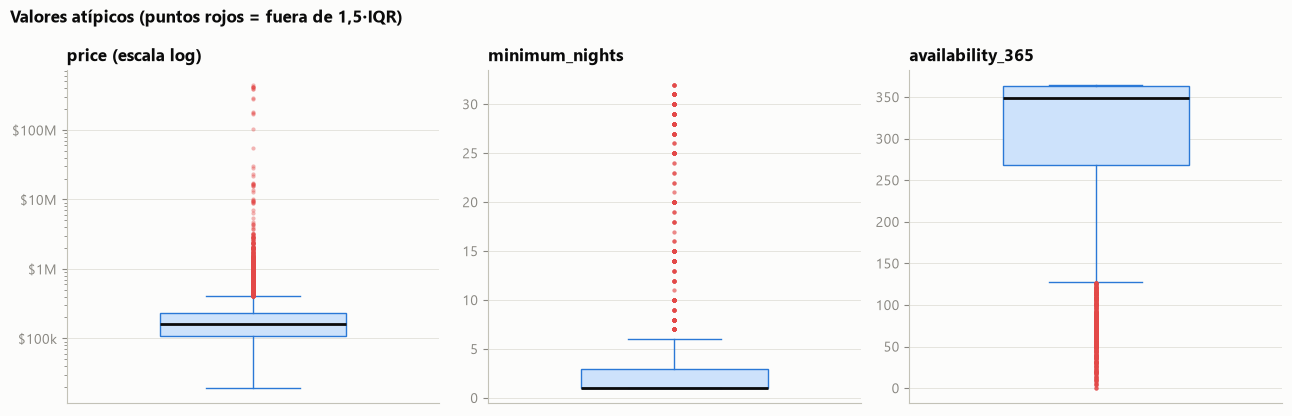

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
props = dict(boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL), medianprops=dict(color=TINTA, linewidth=2),
             whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
             flierprops=dict(marker="o", markersize=3, markerfacecolor=ROJO, markeredgecolor="none", alpha=.4))
axes[0].boxplot(listings["price_num"].dropna(), patch_artist=True, widths=.5, **props)
axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(COP)
axes[0].set_title("price (escala log)")
axes[1].boxplot(listings["minimum_nights"].dropna(), patch_artist=True, widths=.5, **props)
axes[1].set_title("minimum_nights")
axes[2].boxplot(listings["availability_365"].dropna(), patch_artist=True, widths=.5, **props)
axes[2].set_title("availability_365")
for ax in axes:
    ax.set_xticks([])
fig.suptitle("Valores atípicos (puntos rojos = fuera de 1,5·IQR)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "fig02_boxplots_atipicos")
plt.show()

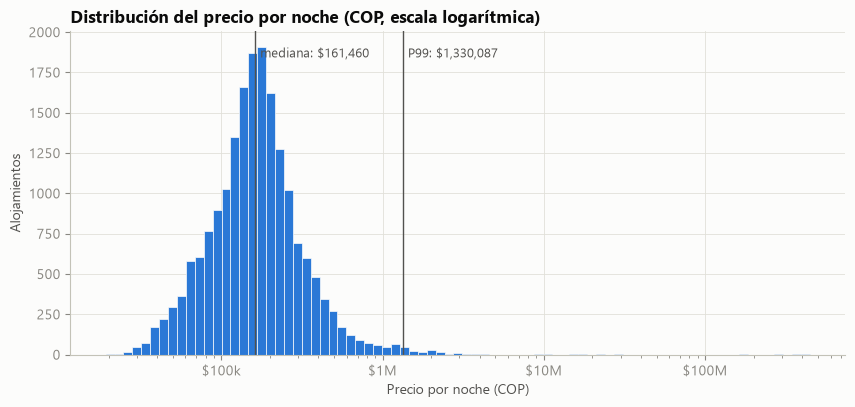

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.2))
precios = listings["price_num"].dropna()
bins = np.logspace(np.log10(precios.min()), np.log10(precios.max()), 80)
ax.hist(precios, bins=bins, color=AZUL, edgecolor=FONDO, linewidth=0.5)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(COP)
for valor, etiqueta in [(precios.median(), "mediana"), (precios.quantile(.99), "P99")]:
    ax.axvline(valor, color=TINTA_2, linewidth=1)
    ax.text(valor * 1.08, ax.get_ylim()[1] * .95, f"{etiqueta}: ${valor:,.0f}", color=TINTA_2, va="top", fontsize=9)
ax.set_title("Distribución del precio por noche (COP, escala logarítmica)")
ax.set_xlabel("Precio por noche (COP)"); ax.set_ylabel("Alojamientos")
guardar(fig, "fig03_distribucion_precio")
plt.show()

**Interpretación**

- **`price`:** distribución muy asimétrica a la derecha. La mitad de los alojamientos cuesta menos de
  ~161 mil COP/noche y el 99 % menos de ~1,33 millones, pero el máximo es de **448 millones**. En escala
  logarítmica la distribución es aproximadamente normal, por eso el IQR sobre el logaritmo es el criterio
  adecuado: marca ~660 alojamientos (3,5 %) como atípicos (< ~36 mil o > ~700 mil COP).
  **Decisión:** no se eliminan (muchos son alojamientos de lujo o habitaciones muy económicas reales); se
  marcan con `precio_outlier` y se crea `price_ajustado`, recortado a los percentiles 1–99, para que
  promedios y tableros no se distorsionen.
- **`minimum_nights`:** el IQR marca como atípicos los mínimos de 30 noches, pero **no son errores**:
  el 17 % de la oferta exige estadías mensuales (mercado de arriendo de mediano plazo). Se conservan;
  el valor máximo (32) es razonable.
- **`availability_365`:** sesgada hacia valores altos (mediana 349 días). El IQR marca los valores bajos,
  que son alojamientos muy reservados o bloqueados; son legítimos. Llama la atención que **3.508
  alojamientos (18 %) están disponibles los 365 días**: podrían ser anuncios inactivos → se crea la bandera
  `disponible_todo_el_anio` en lugar de eliminarlos.
- **`maximum_nights`:** contiene el valor **2.147.483.647** (máximo de un entero de 32 bits), que es un
  marcador técnico de "sin límite". Se acota a 1.125 noches, el máximo que permite Airbnb.

### 3.4 Inconsistencias de formato y de texto

In [18]:
print("Formato de price (texto con $ y separador de miles):")
print(listings["price"].dropna().sample(5, random_state=1).to_string())

print("\nVariantes de escritura en host_location (mismo lugar, distinta forma):")
loc = listings["host_location"].dropna()
for patron in ["^bogot", "^medell", "^colombia"]:
    print(loc[loc.str.lower().str.contains(patron)].value_counts().head(4).to_string(), "\n")

print("Localidades sin tilde en la fuente:", sorted(n for n in listings["neighbourhood_cleansed"].unique()
                                                   if n in ["Usaquen", "Engativa", "Fontibon", "Los Martires",
                                                            "San Cristobal", "Ciudad Bolivar", "Candelaria"]))
print("\nmaximum_nights = 2.147.483.647 en Listings:", (listings["maximum_nights"] == 2147483647).sum(),
      "| en Calendar:", f"{(calendar['maximum_nights'] == 2147483647).sum():,}")
print("Comentarios con etiquetas HTML <br/>:", f"{reviews['comments'].str.contains('<br', regex=False, na=False).sum():,}")
print("Comentarios de 3 caracteres o menos:", f"{reviews['comments'].str.strip().str.len().le(3).sum():,}")
print("has_availability nulo:", listings["has_availability"].isna().sum())
print("Booleanos codificados como texto:", listings["host_is_superhost"].unique())
print("Fechas como texto:", listings[["last_scraped", "first_review"]].dtypes.to_dict())

Formato de price (texto con $ y separador de miles):
4823     $206,095.00
3927      $55,917.67
8955     $225,353.56
10134    $141,339.00
12520    $138,654.00

Variantes de escritura en host_location (mismo lugar, distinta forma):
host_location
Bogotá, Colombia    9451
Bogota, Colombia    2253
Bogota, NJ             1
Bogota, IL             1 

host_location
Medellín, Colombia    124
Medellin, Colombia     53 

host_location
Colombia              426
Colombia, Colombia     56
Colombia, Peru          1 

Localidades sin tilde en la fuente: ['Candelaria', 'Ciudad Bolivar', 'Engativa', 'Fontibon', 'Los Martires', 'San Cristobal', 'Usaquen']

maximum_nights = 2.147.483.647 en Listings: 4 | en Calendar: 1,458


Comentarios con etiquetas HTML <br/>: 69,375


Comentarios de 3 caracteres o menos: 5,280
has_availability nulo: 130
Booleanos codificados como texto: <StringArray>
['t', 'f']
Length: 2, dtype: str
Fechas como texto: {'last_scraped': <StringDtype(storage='python', na_value=nan)>, 'first_review': <StringDtype(storage='python', na_value=nan)>}


**Interpretación:** el dataset es técnicamente consistente (llaves únicas, integridad referencial), pero
tiene **problemas de formato** que impiden el análisis directo:

1. **Moneda:** el precio es texto (`"$284,294.01"`) → hay que quitar `$` y `,` y convertir a número.
2. **Texto:** el mismo lugar aparece escrito de varias formas (`Bogota` / `Bogotá`, `Medellin` / `Medellín`,
   `Colombia, Colombia`) y las localidades vienen sin tildes ni el nombre oficial (`Candelaria` →
   *La Candelaria*). Sin unificar, un `GROUP BY` partiría la misma ciudad en varios grupos.
3. **Fechas y booleanos** como texto (`'2026-06-22'`, `'t'`/`'f'`) → convertir a fecha ISO y a 1/0.
4. **HTML** dentro de los comentarios (`<br/>` en ~69 mil reseñas).
5. **Valores técnicos** en `maximum_nights` (2.147.483.647).

## 4. Distribuciones y relaciones

### 4.1 Tipo de alojamiento

,alojamientos,precio_mediano,participacion
room_type,,,
Entire home/apt,13865,"182,589.00",0.72
Private room,5172,"91,295.00",0.27
Shared room,117,"41,453.00",0.01
Hotel room,33,"193,048.00",0.00


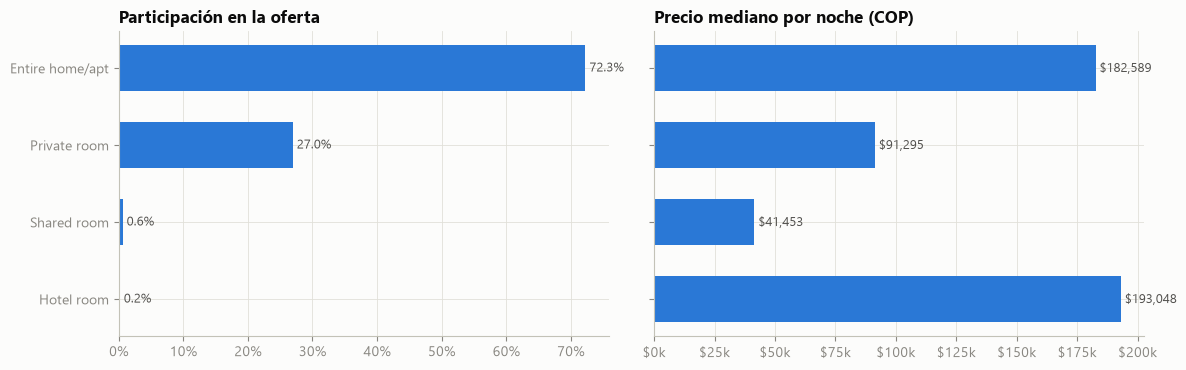

In [19]:
por_tipo = (listings.groupby("room_type")
            .agg(alojamientos=("id", "size"), precio_mediano=("price_num", "median"))
            .sort_values("alojamientos", ascending=False))
por_tipo["participacion"] = por_tipo["alojamientos"] / por_tipo["alojamientos"].sum()
display(por_tipo)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].barh(por_tipo.index[::-1], por_tipo["participacion"][::-1], color=AZUL, height=.6)
axes[0].xaxis.set_major_formatter(PCT); axes[0].set_title("Participación en la oferta")
for i, v in enumerate(por_tipo["participacion"][::-1]):
    axes[0].text(v, i, f" {v:.1%}", va="center", fontsize=9, color=TINTA_2)
axes[1].barh(por_tipo.index[::-1], por_tipo["precio_mediano"][::-1], color=AZUL, height=.6)
axes[1].xaxis.set_major_formatter(COP); axes[1].set_title("Precio mediano por noche (COP)")
for i, v in enumerate(por_tipo["precio_mediano"][::-1]):
    axes[1].text(v, i, f" ${v:,.0f}", va="center", fontsize=9, color=TINTA_2)
axes[1].set_yticklabels([])
fig.tight_layout()
guardar(fig, "fig04_tipo_alojamiento")
plt.show()

**Interpretación:** la oferta de Bogotá está dominada por **apartamentos completos (72 %)**, seguidos por
habitaciones privadas (27 %); habitaciones compartidas y de hotel son marginales (< 1 %). Un apartamento
completo cuesta en mediana **el doble** que una habitación privada (~183 mil vs ~91 mil COP). Como el tipo de
alojamiento cambia tanto el precio, la **imputación de precios faltantes se hace por localidad *y* tipo de
habitación**, no con una mediana global.

### 4.2 Localidades: oferta y precio

,alojamientos,precio_mediano,calificacion_mediana,participacion
neighbourhood_cleansed,,,,
Chapinero,5097,"199,111.87",4.82,0.27
Usaquen,3582,"194,001.00",4.82,0.19
Teusaquillo,2779,"136,479.00",4.82,0.14
Santa Fe,1453,"149,562.66",4.87,0.08
Suba,1274,"136,941.33",4.89,0.07
Engativa,1211,"112,347.00",4.83,0.06
Barrios Unidos,1036,"142,647.50",4.84,0.05
Fontibon,969,"136,942.00",4.84,0.05
Candelaria,700,"136,941.24",4.82,0.04


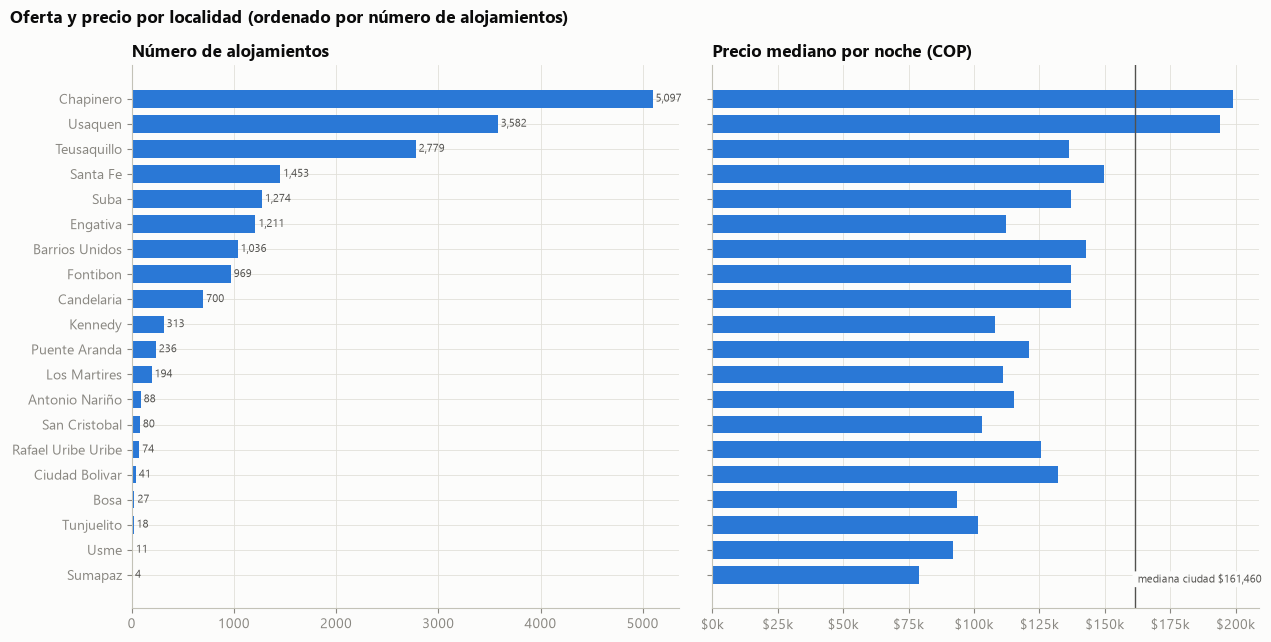

In [20]:
por_localidad = (listings.groupby("neighbourhood_cleansed")
                 .agg(alojamientos=("id", "size"), precio_mediano=("price_num", "median"),
                      calificacion_mediana=("review_scores_rating", "median"))
                 .sort_values("alojamientos", ascending=False))
por_localidad["participacion"] = por_localidad["alojamientos"] / len(listings)
display(por_localidad)

orden = por_localidad.sort_values("alojamientos").index
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
axes[0].barh(orden, por_localidad.loc[orden, "alojamientos"], color=AZUL, height=.7)
axes[0].set_title("Número de alojamientos")
for i, v in enumerate(por_localidad.loc[orden, "alojamientos"]):
    axes[0].text(v, i, f" {v:,}", va="center", fontsize=8, color=TINTA_2)
axes[1].barh(orden, por_localidad.loc[orden, "precio_mediano"], color=AZUL, height=.7)
axes[1].xaxis.set_major_formatter(COP); axes[1].set_title("Precio mediano por noche (COP)")
mediana_ciudad = listings["price_num"].median()
axes[1].axvline(mediana_ciudad, color=TINTA_2, linewidth=1)
axes[1].text(mediana_ciudad, -0.4, f" mediana ciudad ${mediana_ciudad:,.0f}", fontsize=8, color=TINTA_2,
             va="bottom", bbox=dict(boxstyle="round,pad=0.2", fc=FONDO, ec="none"))
fig.suptitle("Oferta y precio por localidad (ordenado por número de alojamientos)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "fig05_localidades")
plt.show()

**Interpretación:** la oferta está **muy concentrada**: Chapinero (27 %), Usaquén (19 %) y Teusaquillo (14 %)
reúnen el 60 % de los alojamientos. Chapinero y Usaquén —zonas de negocios, vida nocturna y estratos altos—
también son las más caras (~195-200 mil COP de mediana), mientras que las localidades del sur (Bosa, Usme,
Tunjuelito, San Cristóbal) tienen precios cercanos a 90-100 mil COP pero muy pocos alojamientos
(Sumapaz, zona rural, solo tiene 4). Esto confirma que **la localidad es una variable clave** para la
imputación del precio y para cualquier tablero. Las localidades con muy pocos alojamientos deben
interpretarse con cautela (medianas poco estables).

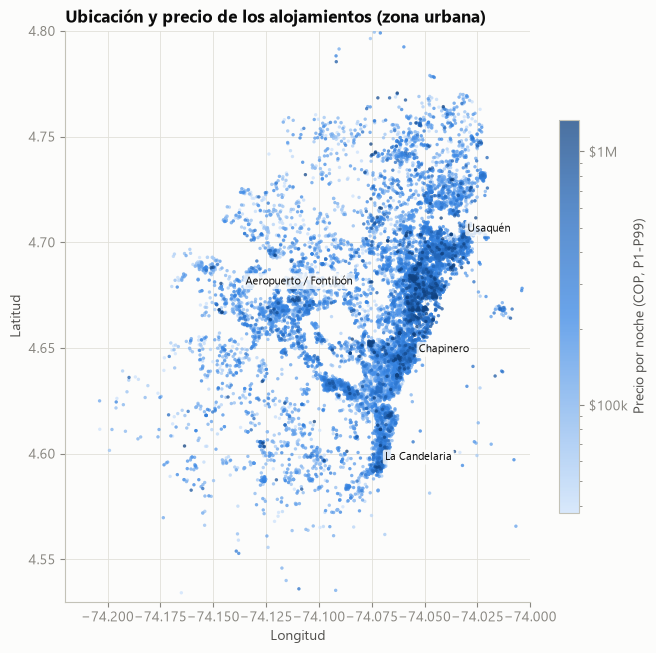

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 8.5))
mapa = listings.dropna(subset=["price_num"]).copy()
mapa["precio_rec"] = mapa["price_num"].clip(*mapa["price_num"].quantile([.01, .99]))
mapa = mapa.sort_values("precio_rec")
sc = ax.scatter(mapa["longitude"], mapa["latitude"], c=mapa["precio_rec"], cmap=SECUENCIAL,
                norm=plt.matplotlib.colors.LogNorm(), s=6, alpha=.75, linewidths=0)
cb = fig.colorbar(sc, ax=ax, shrink=.6, format=COP); cb.set_label("Precio por noche (COP, P1-P99)")
ax.set_xlim(-74.22, -74.00); ax.set_ylim(4.53, 4.80)
ax.set_aspect("equal"); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.set_title("Ubicación y precio de los alojamientos (zona urbana)")
for nombre, (lon, lat) in {"Chapinero": (-74.058, 4.648), "Usaquén": (-74.035, 4.705),
                           "La Candelaria": (-74.074, 4.597), "Aeropuerto / Fontibón": (-74.140, 4.680)}.items():
    ax.annotate(nombre, (lon, lat), xytext=(8, 0), textcoords="offset points", fontsize=8, color=TINTA,
                bbox=dict(boxstyle="round,pad=0.2", fc=FONDO, ec="none", alpha=.8))
guardar(fig, "fig06_mapa_precios")
plt.show()

**Interpretación:** el mapa muestra un **corredor nororiental** (Chapinero – Usaquén, a lo largo de los cerros)
con la mayor densidad de alojamientos y los precios más altos (tonos oscuros). Hacia el occidente y el sur
la densidad baja y predominan los tonos claros (precios menores). También se observa un núcleo en el centro
histórico (La Candelaria / Santa Fe), orientado a turismo cultural, y otro cerca del aeropuerto (Fontibón).
Las coordenadas están todas dentro de Bogotá (incluida la zona rural de Sumapaz, fuera del recuadro),
por lo que **no hay registros con ubicación errónea**.

### 4.3 Noches mínimas y disponibilidad

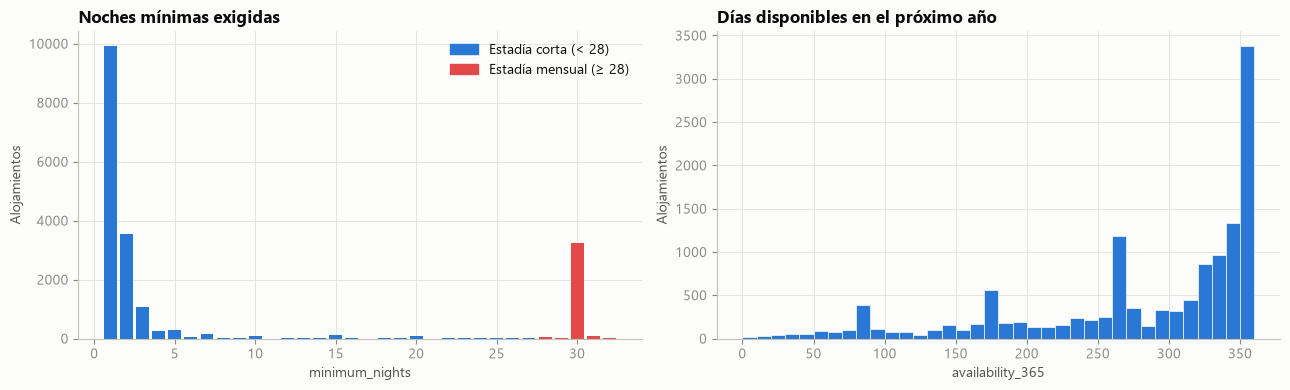

Exigen 1 noche: 51.7% | exigen 28+ noches: 17.8% | disponibles 365 días: 18.3%


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
conteo = listings["minimum_nights"].value_counts().sort_index()
colores = [ROJO if n >= 28 else AZUL for n in conteo.index]
axes[0].bar(conteo.index, conteo.values, color=colores, width=.8)
axes[0].set_title("Noches mínimas exigidas"); axes[0].set_xlabel("minimum_nights"); axes[0].set_ylabel("Alojamientos")
axes[0].legend(handles=[Patch(color=AZUL, label="Estadía corta (< 28)"),
                        Patch(color=ROJO, label="Estadía mensual (≥ 28)")])
axes[1].hist(listings["availability_365"], bins=np.arange(0, 370, 10), color=AZUL, edgecolor=FONDO, linewidth=.5)
axes[1].set_title("Días disponibles en el próximo año"); axes[1].set_xlabel("availability_365"); axes[1].set_ylabel("Alojamientos")
fig.tight_layout()
guardar(fig, "fig07_noches_disponibilidad")
plt.show()

print(f"Exigen 1 noche: {(listings['minimum_nights'] == 1).mean():.1%} | "
      f"exigen 28+ noches: {(listings['minimum_nights'] >= 28).mean():.1%} | "
      f"disponibles 365 días: {(listings['availability_365'] == 365).mean():.1%}")

**Interpretación:** el mercado tiene **dos segmentos claros**: el turístico de estadía corta (52 % acepta una sola
noche) y uno de **arriendo mensual** (~18 % exige 28 o más noches, con un pico en 30). La disponibilidad está
concentrada cerca de 365 días: la mayoría de los calendarios está abierta casi todo el año, y un 18 % no tiene
ningún día ocupado o bloqueado, lo que puede indicar anuncios inactivos o con baja demanda. Ambas variables
son legítimas (no errores), por lo que **no se eliminan registros**; se usan para segmentar.

### 4.4 Correlaciones entre variables numéricas

Se usa la correlación de **Spearman** (por rangos) porque el precio y los conteos de reseñas son muy
asimétricos y tienen atípicos; Spearman es robusta a ambos.

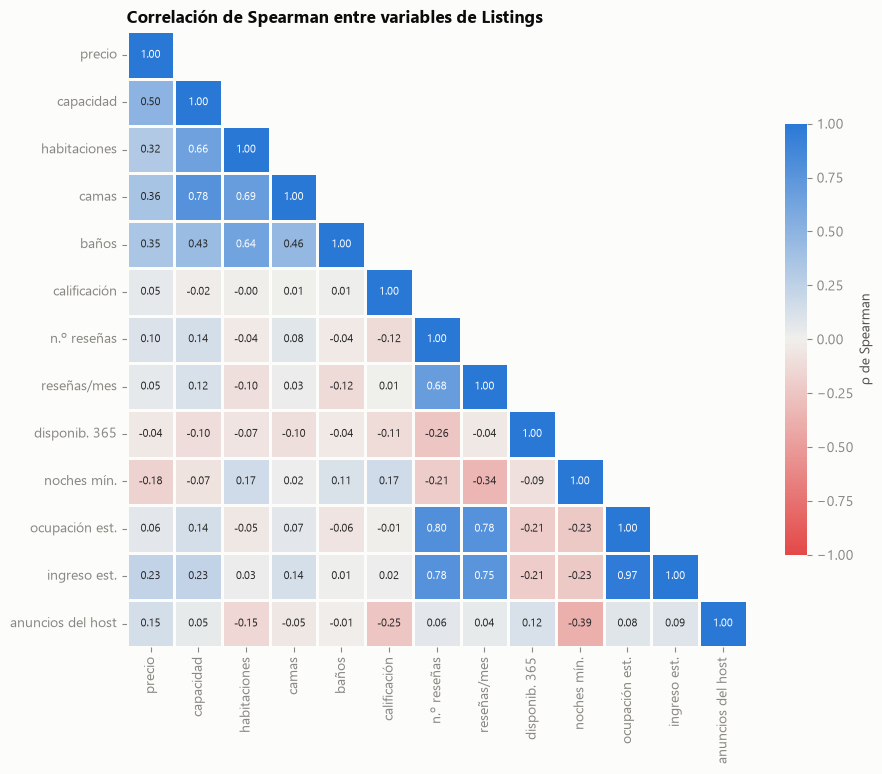

,ρ con el precio
capacidad,0.50
camas,0.36
baños,0.35
habitaciones,0.32
ingreso est.,0.23
anuncios del host,0.15
n.º reseñas,0.10
ocupación est.,0.06
calificación,0.05
reseñas/mes,0.05


In [23]:
vars_corr = {"price_num": "precio", "accommodates": "capacidad", "bedrooms": "habitaciones", "beds": "camas",
             "bathrooms": "baños", "review_scores_rating": "calificación", "number_of_reviews": "n.º reseñas",
             "reviews_per_month": "reseñas/mes", "availability_365": "disponib. 365", "minimum_nights": "noches mín.",
             "estimated_occupancy_l365d": "ocupación est.", "estimated_revenue_l365d": "ingreso est.",
             "calculated_host_listings_count": "anuncios del host"}
corr = listings[list(vars_corr)].rename(columns=vars_corr).corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, cmap=DIVERGENTE, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1, linecolor=FONDO, cbar_kws={"shrink": .7, "label": "ρ de Spearman"}, ax=ax)
ax.set_title("Correlación de Spearman entre variables de Listings")
ax.grid(False)
guardar(fig, "fig08_correlaciones")
plt.show()
corr["precio"].drop("precio").sort_values(ascending=False).to_frame("ρ con el precio")

**Interpretación**

- El precio se relaciona sobre todo con el **tamaño del alojamiento**: capacidad (ρ ≈ 0,50), camas, baños y
  habitaciones (ρ ≈ 0,32-0,37). Es la relación esperable y confirma que el precio limpio tiene sentido.
- La **calificación prácticamente no se relaciona con el precio** (ρ ≈ 0,05): pagar más no garantiza mejor
  experiencia percibida.
- `noches mín.` tiene relación negativa con precio y reseñas: los alojamientos mensuales tienen un precio por
  noche menor y rotan menos huéspedes (menos reseñas).
- `n.º reseñas`, `reseñas/mes`, `ocupación est.` e `ingreso est.` están **muy correlacionadas entre sí**
  (ρ 0,7-0,97) porque Inside Airbnb estima la ocupación a partir de las reseñas: son variables
  **redundantes**, no evidencia independiente de demanda.
- Los anfitriones con muchos anuncios tienen calificaciones algo menores (ρ ≈ −0,25) y exigen menos noches
  mínimas (ρ ≈ −0,39): la gestión profesional prioriza rotación sobre experiencia.

### 4.5 Amenities (campo anidado)

Ejemplo del valor crudo: ["Blender", "Luggage dropoff allowed", "Long term stays allowed", "Children\u2019s dinnerware", "Drying rack for clothing", "Free parking on premises", "Challenger gas stove", "Clothing storage", "Toa ...
Amenities por alojamiento: mediana 26, máximo 90
Amenities distintas: 3,690


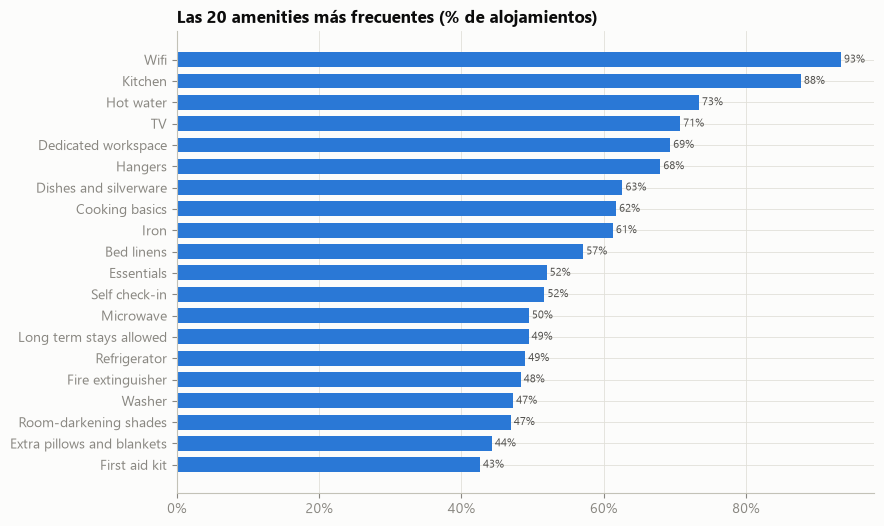

In [24]:
listas = listings["amenities"].apply(lambda v: json.loads(v) if isinstance(v, str) else [])
print("Ejemplo del valor crudo:", listings["amenities"].iloc[0][:200], "...")
print(f"Amenities por alojamiento: mediana {listas.str.len().median():.0f}, máximo {listas.str.len().max()}")
frecuencia = listas.explode().value_counts()
print(f"Amenities distintas: {len(frecuencia):,}")

top = (frecuencia.head(20) / len(listings)).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=AZUL, height=.7)
ax.xaxis.set_major_formatter(PCT)
for i, v in enumerate(top.values):
    ax.text(v, i, f" {v:.0%}", va="center", fontsize=8, color=TINTA_2)
ax.set_title("Las 20 amenities más frecuentes (% de alojamientos)")
guardar(fig, "fig09_amenities")
plt.show()

**Interpretación:** `amenities` es una **lista JSON guardada como texto** con ~26 servicios por alojamiento y
**más de 3.600 valores distintos** (muchos son variantes como "Samsung 42\" HDTV"). Wifi (93 %) y cocina (88 %)
son prácticamente estándar, mientras que el aire acondicionado es poco frecuente (clima frío de Bogotá).
Así como está, el campo no se puede filtrar ni agregar en SQL → **debe desanidarse** en una tabla larga
(alojamiento, amenity) y en columnas 0/1 para las amenities de mayor valor de negocio.

### 4.6 Anfitriones (información del host)

Anfitriones únicos: 8,335 para 19,187 alojamientos


,% de anfitriones,% de alojamientos
calculated_host_listings_count,,
Individual (1),71.5%,31.1%
Pequeño (2-5),21.5%,25.8%
Profesional (6+),7.0%,43.2%


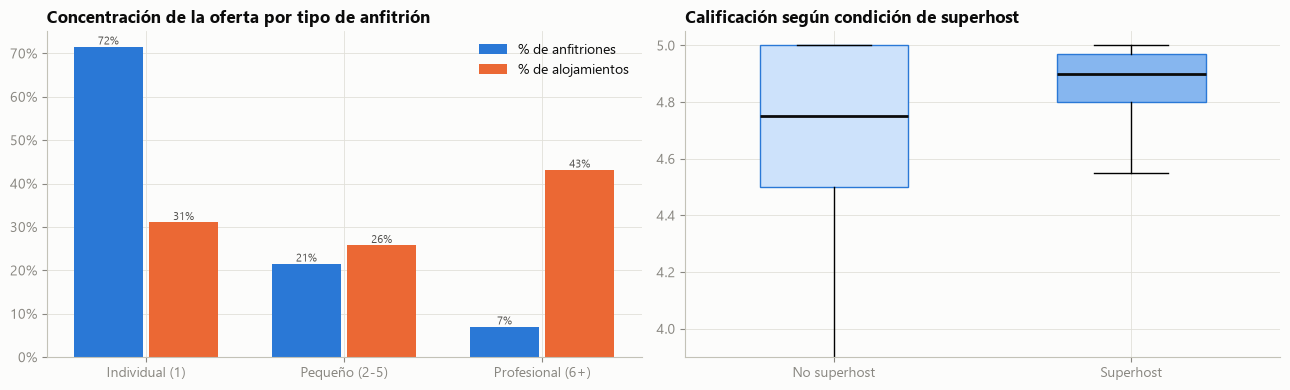

,review_scores_rating,number_of_reviews,price_num
host_is_superhost,,,
f,4.75,3.00,"154,059.00"
t,4.90,24.00,"174,750.00"


In [25]:
hosts = listings.drop_duplicates("host_id")
tipo = pd.cut(hosts["calculated_host_listings_count"], [0, 1, 5, np.inf],
              labels=["Individual (1)", "Pequeño (2-5)", "Profesional (6+)"])
tipo_listing = pd.cut(listings["calculated_host_listings_count"], [0, 1, 5, np.inf],
                      labels=["Individual (1)", "Pequeño (2-5)", "Profesional (6+)"])
concentracion = pd.DataFrame({"% de anfitriones": tipo.value_counts(normalize=True),
                              "% de alojamientos": tipo_listing.value_counts(normalize=True)}).sort_index()
print(f"Anfitriones únicos: {len(hosts):,} para {len(listings):,} alojamientos")
display(concentracion.style.format("{:.1%}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(concentracion)); ancho = .38
for j, col in enumerate(concentracion.columns):
    barras = axes[0].bar(x + (j - .5) * ancho, concentracion[col], ancho * .92, color=PALETA[j], label=col)
    axes[0].bar_label(barras, labels=[f"{v:.0%}" for v in concentracion[col]], fontsize=8, color=TINTA_2)
axes[0].set_xticks(x, concentracion.index); axes[0].yaxis.set_major_formatter(PCT)
axes[0].set_title("Concentración de la oferta por tipo de anfitrión"); axes[0].legend()

sh = listings.dropna(subset=["review_scores_rating"])
grupos = [sh.loc[sh["host_is_superhost"] == v, "review_scores_rating"] for v in ["f", "t"]]
partes = axes[1].boxplot(grupos, patch_artist=True, widths=.5, showfliers=False,
                         medianprops=dict(color=TINTA, linewidth=2))
for caja, color in zip(partes["boxes"], ["#cde2fb", "#86b6ef"]):
    caja.set_facecolor(color); caja.set_edgecolor(AZUL)
axes[1].set_xticks([1, 2], ["No superhost", "Superhost"])
axes[1].set_ylim(3.9, 5.05); axes[1].set_title("Calificación según condición de superhost")
fig.tight_layout()
guardar(fig, "fig10_anfitriones")
plt.show()
listings.groupby("host_is_superhost")[["review_scores_rating", "number_of_reviews", "price_num"]].median()

**Interpretación:** hay **8.335 anfitriones para 19.187 alojamientos**. El 72 % de los anfitriones tiene un solo
anuncio, pero el **7 % "profesional" (6 o más anuncios) controla el 43 % de la oferta**: el mercado está
bastante profesionalizado. Los superhosts tienen mejor calificación (mediana 4,90 vs 4,75) y muchas más reseñas
(24 vs 3). Como los datos del host (nombre, ubicación, superhost, número de anuncios…) **se repiten en cada uno de
sus alojamientos** —hasta cientos de veces—, conviene **desanidarlos en una dimensión `hosts`** y dejar en
listings solo `host_id` como llave foránea.

## 5. Análisis temporal

### 5.1 Evolución de las reseñas (proxy de la demanda)

date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
reseñas,2,14,26,119,399,946,2571,5365,9951,15051,10393,21289,42420,69607,103814,154156,91608


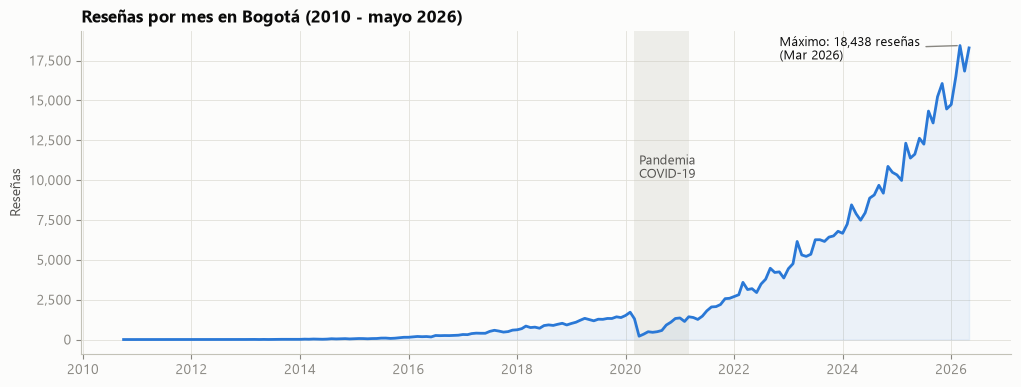

In [26]:
fechas_rev = pd.to_datetime(reviews["date"])
mensual = fechas_rev.dt.to_period("M").value_counts().sort_index()
mensual = mensual[mensual.index < pd.Period("2026-06", "M")]
por_anio = fechas_rev.dt.year.value_counts().sort_index()
display(por_anio.to_frame("reseñas").T)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(mensual.index.to_timestamp(), mensual.values, color=AZUL)
ax.fill_between(mensual.index.to_timestamp(), mensual.values, color=AZUL, alpha=.08)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-03-01"), color=GRIS, alpha=.25, linewidth=0)
ax.text(pd.Timestamp("2020-04-01"), mensual.max() * .55, "Pandemia\nCOVID-19", fontsize=9, color=TINTA_2)
pico = mensual.idxmax()
ax.annotate(f"Máximo: {mensual.max():,} reseñas\n({pico.strftime('%b %Y')})", (pico.to_timestamp(), mensual.max()),
            xytext=(-130, -10), textcoords="offset points", fontsize=9, color=TINTA,
            arrowprops=dict(arrowstyle="-", color=TINTA_SUAVE))
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Reseñas por mes en Bogotá (2010 - mayo 2026)"); ax.set_ylabel("Reseñas")
guardar(fig, "fig11_resenas_tiempo")
plt.show()

**Interpretación:** las reseñas crecen de forma casi exponencial desde 2015. La **pandemia** produjo una caída
clara en 2020 (−31 % frente a 2019; en abril de 2020 casi no hubo reseñas), seguida de una recuperación muy
rápida: 2021 ya superó a 2019 (+41 %) y 2025 cerró con más de **154 mil reseñas**, diez veces el nivel prepandemia.
El máximo mensual se registró en marzo de 2026. Sobre la tendencia se observan **oscilaciones estacionales** (subidas
alrededor de las temporadas de vacaciones y caídas a inicio de año). Para analizar tendencias conviene **resumir las reseñas por
mes** (`reviews_mensual`) y derivar año, mes y trimestre de la fecha.

### 5.2 Calendario: días no disponibles por mes y por día de la semana

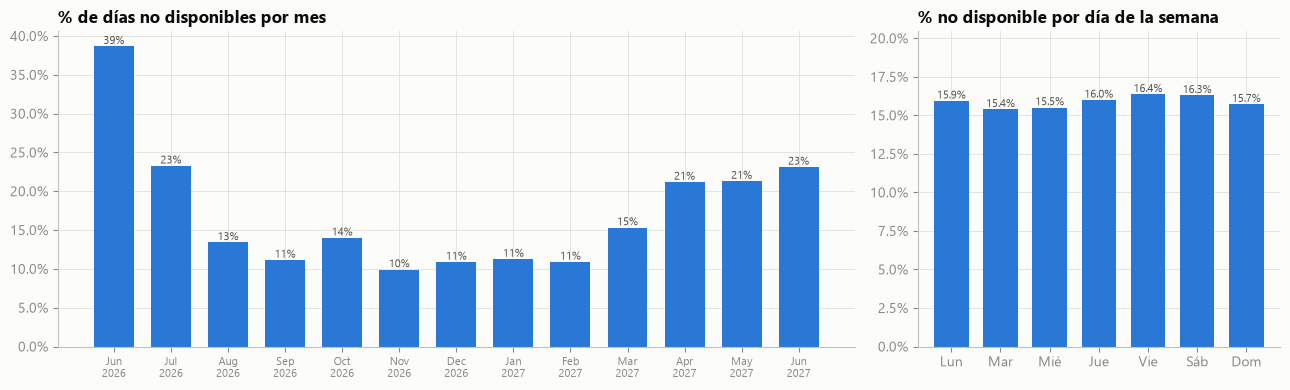

In [27]:
cal_fecha = pd.Series(pd.to_datetime(calendar["date"].cat.categories), index=calendar["date"].cat.categories)
cal = pd.DataFrame({"fecha": calendar["date"].map(cal_fecha).astype("datetime64[ns]"),
                    "no_disponible": (calendar["available"].astype(str) == "f").astype("int8")})
por_mes = cal.groupby(cal["fecha"].dt.to_period("M"))["no_disponible"].mean()
por_dia = cal.groupby(cal["fecha"].dt.dayofweek)["no_disponible"].mean()
por_dia.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(por_mes.index.strftime("%b\n%Y"), por_mes.values, color=AZUL, width=.7)
axes[0].yaxis.set_major_formatter(PCT); axes[0].set_title("% de días no disponibles por mes")
axes[0].tick_params(axis="x", labelsize=8)
for i, v in enumerate(por_mes.values):
    axes[0].text(i, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8, color=TINTA_2)
axes[1].bar(por_dia.index, por_dia.values, color=AZUL, width=.7)
axes[1].yaxis.set_major_formatter(PCT); axes[1].set_title("% no disponible por día de la semana")
axes[1].set_ylim(0, por_dia.max() * 1.25)
for i, v in enumerate(por_dia.values):
    axes[1].text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=8, color=TINTA_2)
fig.tight_layout()
guardar(fig, "fig12_calendario")
plt.show()
del cal

**Interpretación:** el calendario es **prospectivo** (mira hacia el futuro). La no disponibilidad es alta en las
fechas cercanas al scrape (39 % en junio y 23 % en julio de 2026: reservas ya confirmadas para vacaciones de mitad
de año) y baja a ~10-14 % entre septiembre y febrero, cuando aún no se han hecho reservas. El aumento hacia
abril-junio de 2027 se explica más por **bloqueos de calendario** de los anfitriones que abren solo algunos meses
hacia adelante que por demanda real. Por día de la semana la diferencia es mínima (15,4 % - 16,4 %), con jueves a
sábado ligeramente más ocupados. **Conclusión:** `available = 'f'` mezcla reservas y bloqueos, por lo que se
nombrará `no_disponible` (no "ocupado") y se analizará a nivel **mensual y semanal**.

## 6. Posibles transformaciones (2.3)

A continuación se evalúa cada transformación propuesta por la guía y se justifica si es necesaria.

In [28]:
quote = json.loads(listings["price_quote_raw"].dropna().iloc[0])["quote"]
print("Claves del JSON price_quote_raw:", list(quote))
monedas = listings["price_quote_raw"].dropna().map(lambda v: json.loads(v)["quote"].get("currency")).value_counts()
print("Monedas de las cotizaciones:", monedas.to_dict())
print(f"\nFilas de Calendar: {len(calendar):,} vs límite de una hoja de Excel: {MAX_FILAS_EXCEL + 1:,}")
print(f"Filas si se agrupa por alojamiento y mes: ~{calendar['listing_id'].nunique() * 13:,}")
print(f"Repeticiones de datos del host: {len(listings):,} filas para {listings['host_id'].nunique():,} hosts")
print("\nEjemplos de bathrooms_text:", listings["bathrooms_text"].value_counts().head(8).index.tolist())

Claves del JSON price_quote_raw: ['taxes', 'currency', 'date_match', 'service_fee', 'total_price', 'cleaning_fee', 'is_available', 'discount_amount', 'price_per_night', 'nightly_subtotal', 'discounted_subtotal', 'raw_price_line_items', 'returned_checkin_date', 'requested_checkin_date', 'returned_checkout_date', 'requested_checkout_date']
Monedas de las cotizaciones: {'COP': 18993}

Filas de Calendar: 7,003,255 vs límite de una hoja de Excel: 1,048,576
Filas si se agrupa por alojamiento y mes: ~249,431
Repeticiones de datos del host: 19,187 filas para 8,335 hosts

Ejemplos de bathrooms_text: ['1 bath', '2 baths', '1 private bath', '1 shared bath', '1.5 baths', '2.5 baths', '3 baths', '2 shared baths']


| Transformación | ¿Necesaria? | Justificación (evidencia del EDA) |
|---|---|---|
| **Desanidar `amenities`** | **Sí** | Lista JSON en texto con 3.600+ valores; imposible filtrar/agregar en SQL. → tabla `listing_amenities` (formato largo) + `amenities_count` + columnas 0/1 (wifi, cocina, parqueadero, lavadora, etc.). |
| **Desanidar información del host** | **Sí** | 16 columnas `host_*` repetidas en 19.187 filas para solo 8.335 hosts. → dimensión `hosts` con `tipo_anfitrion`; listings conserva `host_id`. |
| **Desanidar `price_quote_raw`** | **Parcial** | JSON con moneda y cargos. Todas las cotizaciones están en **COP** (se valida y se guarda `moneda`); los cargos de limpieza/servicio vienen vacíos y se descartan. |
| **Agrupar calendario por mes/semana** | **Sí** | 7 millones de filas superan el límite de Excel (1.048.576) y el análisis de temporada se hace por mes/semana. → `calendar_mensual` (por alojamiento) y `calendar_semanal` (ciudad). El detalle diario se conserva en SQLite. |
| **Agrupar reseñas por mes** | **Sí** | La tendencia de demanda se analiza mensualmente. → `reviews_mensual`. |
| **Estandarizar fechas** | **Sí** | Fechas en texto → formato ISO **YYYY-MM-DD** + año, mes, día, trimestre, día de la semana, semana ISO y fin de semana. |
| **Estandarizar moneda** | **Sí** | `"$284,294.01"` → `284294.01` (float, COP). Imputación de 195 nulos, bandera de atípicos, `price_ajustado` (P1-P99) y `categoria_precio` por rangos. |
| **Estandarizar texto** | **Sí** | Variantes `Bogota`/`Bogotá`, localidades sin tilde, HTML `<br/>` en comentarios, espacios repetidos. |
| **Booleanos** | **Sí** | `'t'`/`'f'` → 1/0 para poder sumar y promediar. |
| **Eliminar duplicados** | **No (control preventivo)** | No se encontraron, pero el ETL los verifica en cada ejecución. |

## 7. Hallazgos y decisiones para la fase de transformación (2.4)

| # | Hallazgo | Tipo | Decisión en `transformacion.py` |
|---|---|---|---|
| 1 | 13 columnas 100 % vacías y 10 columnas de URLs/IDs técnicos | Variables problemáticas | `_eliminar_columnas_vacias`: se eliminan y se listan en el log |
| 2 | `price` es texto con `$` y `,`; 195 nulos | Inconsistencia de formato | `normalizar_precio` + imputación por mediana de localidad × tipo de habitación, con `precio_imputado` |
| 3 | Precio máximo de 448 millones COP/noche; ~660 atípicos por IQR (log) | Outliers | Se conservan; `precio_outlier` = 1 y `price_ajustado` winsorizado a P1-P99 |
| 4 | Precio sesgado; segmentos claros por tipo/localidad | Distribución | `categoria_precio`: Económico (<100k), Medio (100-200k), Alto (200-400k), Premium (400k-1M), Lujo (≥1M) |
| 5 | `maximum_nights` = 2.147.483.647 | Valor técnico inválido | `acotar_noches`: se acota a 1.125 (máximo de Airbnb) en Listings y Calendar |
| 6 | 22 % sin reseñas → `review_scores_*` nulos | Nulos con significado | No se imputan; bandera `tiene_resenas`; `reviews_per_month` = 0 |
| 7 | `bathrooms` nulo pero `bathrooms_text` disponible | Variable recuperable | `_procesar_banos`: número de baños y `bano_compartido` desde el texto |
| 8 | `bedrooms`/`beds` nulos | Nulos imputables | Habitaciones = 1 en cuartos privados; resto mediana según `accommodates` |
| 9 | Variantes de texto (`Bogota`/`Bogotá`), localidades sin tilde | Inconsistencia de texto | `canonizar_texto` y nombres oficiales de las 20 localidades (`localidad`) |
| 10 | `amenities` JSON con 3.600+ valores | Campo anidado | `_procesar_amenities`: tabla larga, conteo y 14 columnas 0/1 |
| 11 | Datos del host repetidos (8.335 hosts / 19.187 filas); 7 % de hosts tiene el 43 % de la oferta | Redundancia | `_crear_dimension_hosts` con `tipo_anfitrion` |
| 12 | `price_quote_raw` JSON, todo en COP | Campo anidado | `_desanidar_cotizacion`: `moneda` validada, cargos vacíos descartados |
| 13 | Fechas y booleanos como texto | Formato | Fechas a YYYY-MM-DD y variables derivadas; `'t'/'f'` → 1/0 |
| 14 | Calendario de 7 M filas, sin precio; `available='f'` mezcla reservas y bloqueos | Volumen / semántica | `disponible`/`no_disponible`; resúmenes `calendar_mensual` (con ingreso estimado usando `price_ajustado`) y `calendar_semanal` |
| 15 | ~69 mil comentarios con `<br/>`, 191 nulos, ~5 mil de ≤3 caracteres | Calidad de texto | `limpiar_texto`; "Sin comentario" + `comentario_vacio`; `longitud_comentario`, `comentario_corto` |
| 16 | 18 % de alojamientos disponibles 365 días | Posibles anuncios inactivos | Bandera `disponible_todo_el_anio` (no se eliminan) |
| 17 | Sin duplicados ni registros huérfanos | Calidad | Controles preventivos de duplicados e integridad referencial |
| 18 | `n.º reseñas`, ocupación e ingreso estimados muy correlacionados (ρ 0,7-0,97) | Correlación / redundancia | Se conservan pero se documenta que no son evidencia independiente |

**Conclusión del EDA:** los datos de Inside Airbnb para Bogotá son **completos en sus llaves y consistentes entre
colecciones**, pero requieren una **limpieza de formato** importante (moneda, fechas, booleanos, texto), el
**tratamiento de valores extremos** en precio y noches, y la **normalización de campos anidados** (amenities,
host, cotización) para que puedan cargarse y consultarse en una base de datos relacional.

## 8. Verificación del resultado del ETL

Si ya se ejecutó `python src/main.py`, se lee la base SQLite generada para comprobar que las decisiones
anteriores quedaron aplicadas.

In [29]:
import sqlite3
if RUTA_SQLITE.exists():
    with sqlite3.connect(RUTA_SQLITE) as con:
        tablas = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con)["name"]
        conteos = pd.DataFrame({"tabla": tablas,
                                "registros": [pd.read_sql(f"SELECT COUNT(*) n FROM {t}", con)["n"][0] for t in tablas]})
        display(conteos)
        display(pd.read_sql("SELECT * FROM auditoria_transformaciones", con))
        categorias = pd.read_sql(
            "SELECT categoria_precio, COUNT(*) AS alojamientos, ROUND(AVG(price_ajustado)) AS precio_promedio "
            "FROM listings GROUP BY categoria_precio", con)
        antes_despues = pd.read_sql(
            "SELECT MIN(price) min, AVG(price) promedio, MAX(price) max, AVG(price_ajustado) promedio_ajustado, "
            "SUM(precio_imputado) imputados, SUM(precio_outlier) outliers FROM listings", con)
else:
    print("Aún no existe la base SQLite: ejecute primero  python src/main.py")

,tabla,registros
0,amenities_resumen,3687
1,auditoria_transformaciones,22
2,calendar,7003255
3,calendar_mensual,249431
4,calendar_semanal,54
5,hosts,8335
6,listing_amenities,505595
7,listings,19187
8,reviews,527731
9,reviews_mensual,182


,tabla,paso,filas_antes,filas_despues,detalle
0,listings,Eliminar duplicados,19187,19187,duplicados por ['id'] = 0
1,listings,Eliminar columnas vacías/irrelevantes,19187,19187,13 vacías + 9 irrelevantes; quedan 68 columnas
2,listings,Desanidar price_quote_raw (JSON),19187,19187,monedas={'COP': 19187}
3,listings,"Normalizar precio ($ y , -> número COP)",19187,19187,"imputados=195, outliers=667, winsorizado P1=37..."
4,listings,Categorizar precio por rangos,19187,19187,"{'Medio': 8680, 'Alto': 4946, 'Económico': 406..."
5,listings,Booleanos t/f -> 1/0,19187,19187,"host_is_superhost, host_has_profile_pic, host_..."
6,listings,Fechas -> YYYY-MM-DD,19187,19187,"last_scraped, first_review, last_review, price..."
7,listings,Tratar valores nulos,19187,19187,"celdas nulas 98,970 -> 87,996 (review_scores s..."
8,listings,Derivar baños desde bathrooms_text,19187,19187,bathrooms nulos 1066 -> 0
9,listings,Estandarizar textos y localidades,19187,19187,20 localidades oficiales


,min,promedio,max,promedio_ajustado,imputados,outliers
0,"19,181.11","442,994.94","448,176,567.00","205,805.66",195,667


,alojamientos,precio_promedio
categoria_precio,,
Económico,4062,"70,870.00"
Medio,8680,"149,425.00"
Alto,4946,"265,885.00"
Premium,1192,"555,370.00"
Lujo,307,"1,260,068.00"


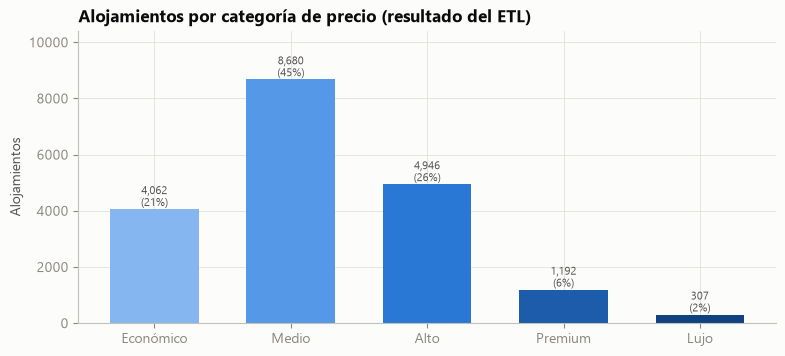

In [30]:
if RUTA_SQLITE.exists():
    display(antes_despues)
    orden_cat = ["Económico", "Medio", "Alto", "Premium", "Lujo"]
    categorias = categorias.set_index("categoria_precio").loc[orden_cat]
    display(categorias)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    rampa = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
    barras = ax.bar(categorias.index, categorias["alojamientos"], color=rampa, width=.65)
    ax.bar_label(barras, labels=[f"{v:,}\n({v / categorias['alojamientos'].sum():.0%})" for v in categorias["alojamientos"]],
                 fontsize=8, color=TINTA_2)
    ax.set_ylim(0, categorias["alojamientos"].max() * 1.2)
    ax.set_title("Alojamientos por categoría de precio (resultado del ETL)"); ax.set_ylabel("Alojamientos")
    guardar(fig, "fig13_categoria_precio")
    plt.show()

**Interpretación:** tras el ETL, el precio es numérico (REAL en SQLite), el promedio ajustado ya no está distorsionado
por el valor de 448 millones, y la oferta queda segmentada en categorías: la mayoría de alojamientos está en el rango
**Medio (100-200 mil COP)**, seguido de Alto y Económico; Premium y Lujo suman cerca del 8 %. La tabla de auditoría
muestra, paso a paso, las filas antes y después de cada transformación, coherente con los hallazgos de este notebook.